# 142–143 · A safety shield for TableTop, and systematic fault injection

In [1]:
import numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, ExpertPolicy

class Limits:
    max_force = 25.0
    box = (np.array([0.25, -0.35, 0.0]), np.array([0.75, 0.35, 0.60]))   # must contain the home pose (z = 0.52 m)
    max_step = 0.06                                                      # just above the 5 cm/step action limit

class Shield:
    """Cheap checks that run every control step, independent of the network that produced the action."""
    def __init__(self, env, limits=Limits):
        self.env, self.L, self.log = env, limits, []
    def __call__(self, env, obs, a):
        f = np.linalg.norm(env.wrist_force())
        nxt = env.target_pos + a[:3]
        checks = {"force": f < self.L.max_force or a[2] > 0,
                  "workspace": bool(np.all(nxt >= self.L.box[0]) and np.all(nxt <= self.L.box[1])),
                  "velocity": float(np.linalg.norm(a[:3])) <= self.L.max_step}
        violated = [k for k, ok in checks.items() if not ok]
        self.log.append(dict(t=env.t, force=f, violated=violated))
        if not violated:
            return a
        hold = np.zeros(7); hold[6] = a[6]
        if "force" in violated:
            hold[2] = 0.01
        return hold

class Faulty(ExpertPolicy):
    def __init__(self, env, fault, at=10):
        super().__init__(env); self.fault, self.at = fault, at
    def act(self, obs):
        a = super().act(obs)
        if self.env.t >= self.at:
            if self.fault == "push_down":
                a[:3] = [0, 0, -0.03]
            elif self.fault == "scale_x5":
                a[:3] *= 5
            elif self.fault == "sign_flip":
                a[:3] *= -1
            elif self.fault == "spike" and np.random.rand() < 0.1:
                a[:3] = np.random.uniform(-0.3, 0.3, 3)
        return a

def episode(env, policy, shield=None, seed=0):
    obs = env.reset(seed=seed); policy.reset(); done, unsafe, forces, zs = False, 0, [], []
    while not done:
        a = policy.act(obs)
        if shield is not None:
            a = shield(env, obs, a)
        obs, _, done, info = env.step(a)
        f = np.linalg.norm(env.wrist_force()); forces.append(f); zs.append(env.state()[2])
        unsafe += int(f > 40 or env.unreachable)
    return info["success"], unsafe, np.array(forces), np.array(zs)

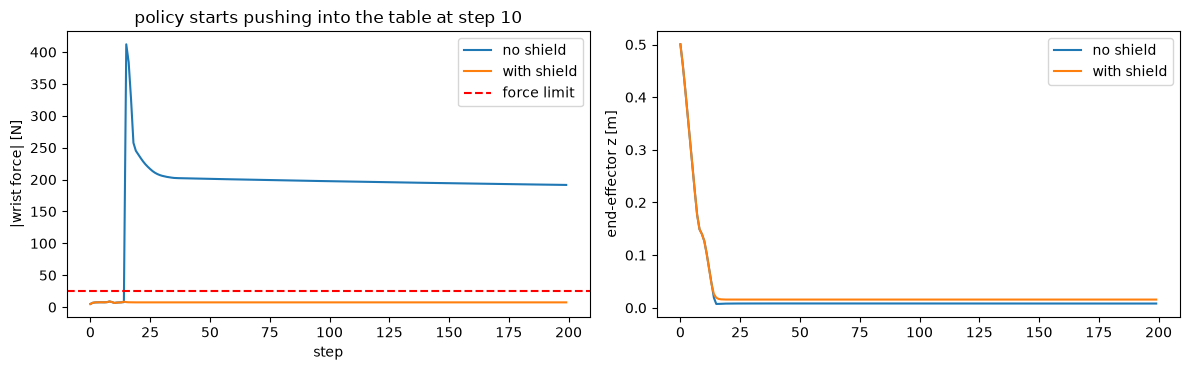

first shield interventions: [{'t': 14, 'force': np.float64(7.363311557114563), 'violated': ['workspace']}, {'t': 15, 'force': np.float64(8.645938817358653), 'violated': ['workspace']}, {'t': 16, 'force': np.float64(7.859036875145994), 'violated': ['workspace']}]


In [2]:
env = TableTop(cameras=(), wrist_ft=True, seed=0)
ok, unsafe, f_free, z_free = episode(env, Faulty(env, "push_down"), None, seed=3)
sh = Shield(env)
ok2, unsafe2, f_sh, z_sh = episode(env, Faulty(env, "push_down"), sh, seed=3)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(f_free, label="no shield"); ax[0].plot(f_sh, label="with shield"); ax[0].axhline(Limits.max_force, c="r", ls="--", label="force limit")
ax[0].set_ylabel("|wrist force| [N]"); ax[0].set_xlabel("step"); ax[0].legend(); ax[0].set_title("policy starts pushing into the table at step 10")
ax[1].plot(z_free, label="no shield"); ax[1].plot(z_sh, label="with shield"); ax[1].set_ylabel("end-effector z [m]"); ax[1].legend(); plt.tight_layout(); plt.show()
print("first shield interventions:", [e for e in sh.log if e["violated"]][:3])

In [3]:
faults = ["none", "push_down", "scale_x5", "sign_flip", "spike"]
rows = []
for fault in faults:
    for use in [False, True]:
        res = [episode(env, Faulty(env, fault) if fault != "none" else ExpertPolicy(env), Shield(env) if use else None, seed=100 + s) for s in range(15)]
        rows.append((fault, use, np.mean([r[0] for r in res]), np.mean([r[1] for r in res]), np.max([r[2].max() for r in res])))
print(f"{'fault':10s} {'shield':6s} {'success':>8s} {'unsafe steps/ep':>16s} {'peak force [N]':>15s}")
for r in rows:
    print(f"{r[0]:10s} {str(r[1]):6s} {r[2]:8.2f} {r[3]:16.1f} {r[4]:15.1f}")
print("\nthe shield never asks WHY the action is bad: its guarantees are stated over sensor values, not over the network")

fault      shield  success  unsafe steps/ep  peak force [N]
none       False      1.00              0.0            10.5
none       True       1.00              0.0            10.5
push_down  False      0.00            185.0           471.9
push_down  True       0.00              0.0             9.1
scale_x5   False      0.00              0.0            12.6
scale_x5   True       0.00              0.0             9.1
sign_flip  False      0.00             36.0             9.8
sign_flip  True       0.00             12.0             9.8
spike      False      0.87              0.5           570.5
spike      True       1.00              0.0            10.5

the shield never asks WHY the action is bad: its guarantees are stated over sensor values, not over the network


### Watch it: a policy that suddenly pushes into the table
Same fault, same episode. Without the shield the arm drives into the table; with it the bad commands are replaced by "hold".

In [4]:
from vlacourse import showcase as sc
sc.compare(env, {"push-down fault, NO shield": Faulty(env, "push_down"), "push-down fault + shield": Faulty(env, "push_down")},
           per_policy_kw={"push-down fault + shield": dict(on_step=Shield(env))}, seed=101, title="142 safety shield off vs on",
           overlay=sc.force_gauge(Limits.max_force),                       # live wrist-force readout on every frame
           footer="")                                                       # keep the bottom free for the force gauge

142 safety shield off vs on: push-down fault, NO shield: failed | push-down fault + shield: failed


[False, False]